# 07 — Native subtraction: TCG − TCL as a function of TCB

**What this notebook does:** demonstrates the non-SSB center mode of `tempus integrate` (`--center EARTH_CENTER --target MOON`), which runs two SSB-centred integrations and subtracts them, and derives the one term that separates this result from the geocentric description of TCG − TCL: the boost / simultaneity term.

**Why it is separate from 08:** a difference of two body time scales lives on **two** worldlines, so — unlike TCX − TCB — a row is undefined until one fixes which pair of events it compares. Notebook 08 treats the unrelated choice of which timescale labels the axis.

**Expected key result:** the secular rate of TCG − TCL equals Kopeikin's published 1.4769 µs/day; the two event pairings differ by a bounded, monthly ≲ 136 µs.

**Required data files:** `../data/ephem/inpop21a_TCB_m100_p100_tcg.dat`


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

from tempus import jd_split, jd_tt_to_tcb
from tempus.model import boost_term
from tempus.ephem import CalcephEphem
from tempus.output import read_csv
from nb_utils import run_tempus_integration, yr_from_jd, DAY_S

eph_file = Path("../data/ephem/inpop21a_TCB_m100_p100_tcg.dat").resolve()
out_csv  = Path("../output/nb07_tcg_tcl.csv").resolve()
J2000_TT = 2451545.0  # J2000.0 in TT (Julian date)


## 1 · TCG − TCL from one command

With a non-SSB `--center`, `tempus integrate` runs both bodies against the SSB and writes their difference — here `TCG_minus_TCL` — on the TCB grid. The run covers 2019.0–2023.25, the window of the Kopeikin comparison.


In [2]:
# Anchor: J2000.0 TT -> TCB (native timescale of this ephemeris), then shift to
# the 2019.0-2023.25 window of the Kopeikin comparison.
start = jd_tt_to_tcb(*jd_split(J2000_TT), eph_file) + 19 * 365.25
end   = start + 4.25 * 365.25

run_tempus_integration(
    eph_file=eph_file, out=out_csv,
    start=start, end=end, jd_step=0.75,
    target="MOON", center="EARTH_CENTER",
);


Ephemeris version: INPOP21A
CALCEPH timescale: 2 (TCB)
Approx. mean drift (TCG-TCL): 0.001345 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb07_tcg_tcl.csv


simultaneity: TCB, mode: bcrs_subtraction


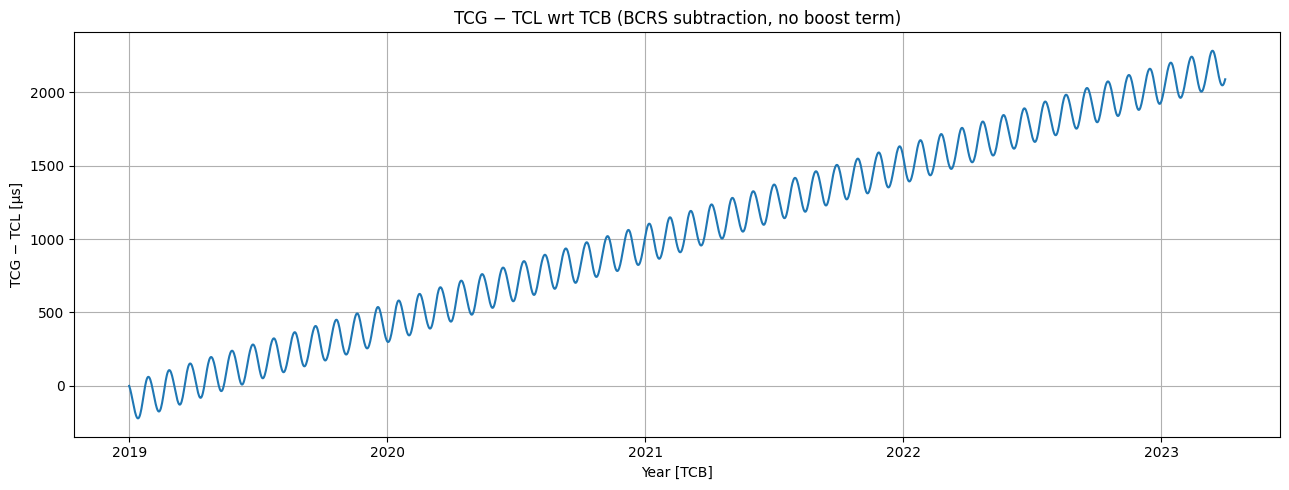

In [3]:
cols, meta = read_csv(out_csv)
jd_int, jd_frac = cols["JD_int"], cols["JD_frac"]
TCG_minus_TCL = cols["TCG_minus_TCL"]
t_yr = yr_from_jd(jd_int + jd_frac)
print(f"simultaneity: {meta['simultaneity']}, mode: {meta['difference_mode']}")

plt.figure(figsize=(13, 5))
plt.plot(t_yr, TCG_minus_TCL * 1e6)
plt.title("TCG − TCL wrt TCB (BCRS subtraction, no boost term)")
plt.xlabel("Year [TCB]")
plt.ylabel("TCG − TCL [µs]")
plt.grid(True)
plt.tight_layout()
plt.show()

## 2 · Which pair of events? The boost term

TCG − TCL compares clocks on two worldlines, so a row means nothing until one fixes which Earth event is paired with which Moon event. The IAU 2000 1PN transformation (Soffel et al. 2003), written as a function of the **field point $\mathbf{x}$** rather than of $t$ alone, shows where that choice enters:

$$\mathrm{TCB}-\mathrm{TCG}(t,\mathbf{x})\;=\;\underbrace{\frac{1}{c^{2}}\int_{t_0}^{t}\!\Big(\tfrac{1}{2}v_E^{2}+U_{\rm ext}(\mathbf{x}_E)\Big)\,d\tau}_{\textstyle A_E(t)\;=\;\texttt{Delta\_TCX}}\;+\;\underbrace{\frac{\mathbf{v}_E\cdot(\mathbf{x}-\mathbf{x}_E)}{c^{2}}}_{\text{simultaneity / boost}}\;+\;\mathcal{O}(c^{-4})$$

$A_E$ is a **worldline** quantity — the integrand is sampled at $\mathbf{x}_E(t)$, so it is what TEMPUS integrates for the Earth centre; the same formula with $E\to L$ holds for the Moon. Pairing the two centres at equal TCB — what the run above writes — gives

$$\mathrm{TCG}(t,\mathbf{x}_E)-\mathrm{TCL}(t,\mathbf{x}_L)\;=\;A_L(t)-A_E(t),$$

while evaluating both at the Moon event — the **geocentric** pairing, à la Kopeikin — keeps TCG's spatial term:

$$\mathrm{TCG}(t,\mathbf{x}_L)-\mathrm{TCL}(t,\mathbf{x}_L)\;=\;A_L(t)-A_E(t)\;-\;\frac{\mathbf{v}_E\cdot\mathbf{r}_{LE}}{c^{2}}.$$

Both are well defined; **they refer to different pairs of events and give different numbers.** The gap is bounded and periodic, ≲ 136 µs monthly, and it is the only piece the subtraction lacks — the tidal dipole is already contained in it. TEMPUS does not apply it: the metadata records `simultaneity: "TCB"`, and `tempus.model.boost_term` converts when the geocentric description is wanted (cf. Klioner 2026, arXiv:2604.16006).

For TCX − TCB, which lives on one worldline, $\mathbf{x}=\mathbf{x}_E$ and the spatial term vanishes identically — which is why notebooks 01–06 never meet it.


boost term: ±135.8 µs peak (monthly)


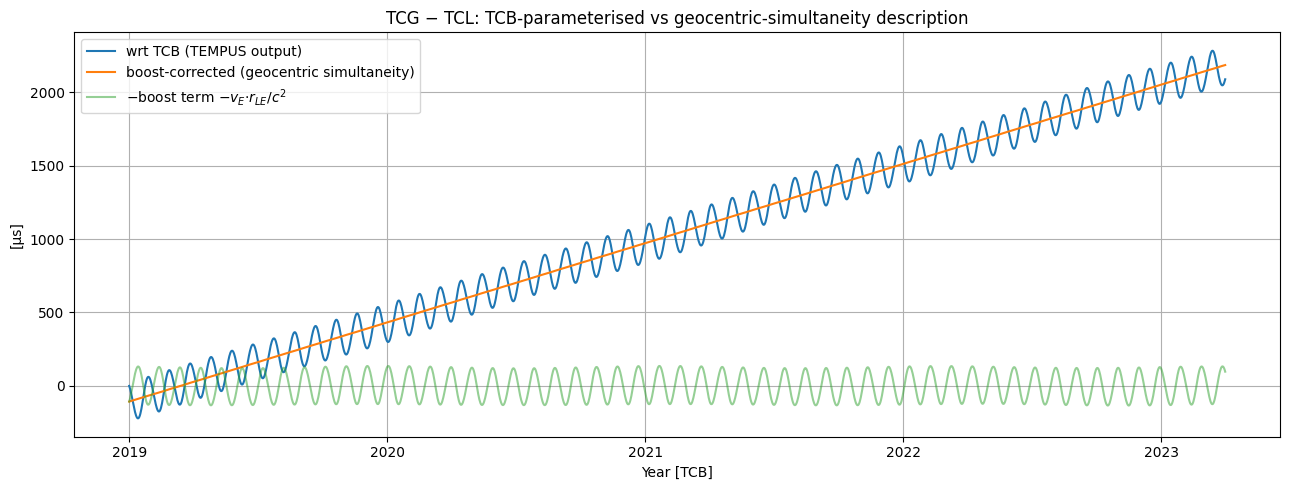

In [4]:
eph = CalcephEphem.open([str(eph_file)])
boost = boost_term(eph, jd_int=jd_int, jd_frac=jd_frac, target=301, center=399)   # v_E . r_LE / c^2
eph.close()
print(f"boost term: ±{np.max(np.abs(boost))*1e6:.1f} µs peak (monthly)")

plt.figure(figsize=(13, 5))
plt.plot(t_yr, TCG_minus_TCL * 1e6, label="wrt TCB (TEMPUS output)")
plt.plot(t_yr, (TCG_minus_TCL - boost) * 1e6, label="boost-corrected (geocentric simultaneity)")
plt.plot(t_yr, -boost * 1e6, label="−boost term −$v_E·r_{LE}/c^2$", alpha=0.5)
plt.title("TCG − TCL: TCB-parameterised vs geocentric-simultaneity description")
plt.xlabel("Year [TCB]")
plt.ylabel("[µs]")
plt.legend(loc="best")
plt.grid(True)
plt.tight_layout()
plt.show()

## 3 · Secular rate against Kopeikin

Kopeikin works in the geocentric description, so the rate is fitted to the boost-corrected series; the boost term is periodic and barely moves it.


In [6]:
slope = stats.linregress(cols["SecondsPastJ2000"] / DAY_S, TCG_minus_TCL - boost).slope
print(f"TCG - TCL secular rate: {slope * 1e6:.4f} µs/day   (Kopeikin: 1.4769 µs/day)")


TCG - TCL secular rate: 1.4769 µs/day   (Kopeikin: 1.4769 µs/day)


**Result:** the one-command subtraction reproduces Kopeikin's published secular rate of TCG − TCL, 1.4769 µs/day, to all four printed decimals. The two event pairings differ only by the bounded, monthly boost term of §2.
